# OCT EDA

run `hash.py`, `dupe.py` and `standardize.py` first

mostly for sanity checking other stuff and ensure consistency across classes/splits/patients etc

In [9]:
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import standardize

DATA_FOLDER = standardize.DATA_FOLDER
CLEAN_FOLDER = standardize.OUTPUT_FOLDER
HASHES_CSV = DATA_FOLDER / "image_hashes.csv"
CLASSES = standardize.CLASSES
SPLITS = standardize.SPLITS
SEED = 7615
THREADS = max(1, (getattr(os, "process_cpu_count", os.cpu_count)() or 1) - 2)  # leave two threads free

for path in [HASHES_CSV, standardize.OMIT_CSV, standardize.LOG_CSV, CLEAN_FOLDER]:
    if not path.exists():
        raise FileNotFoundError(f"{path} not found, run hash.py, dupe.py and standardize.py first")

hashes = pd.read_csv(HASHES_CSV, dtype=str)
omit = pd.read_csv(standardize.OMIT_CSV, dtype=str)
log = pd.read_csv(standardize.LOG_CSV)
log["split"] = log["file"].str.split("/").str[0]
log["class"] = log["file"].str.split("/").str[1]

print(f"hashed: {len(hashes):,}, omitted: {len(omit):,}, cleaned: {len(log):,}")

hashed: 109,309, omitted: 8,135, cleaned: 101,174


In [10]:
plt.rcParams["figure.constrained_layout.use"] = True
CLASS_COLORS = {"CNV": "#2a78d6", "DME": "#eb6834", "DRUSEN": "#1baf7a", "NORMAL": "#eda100"}
COLORS = [CLASS_COLORS[c] for c in CLASSES]


def class_bars(ax, values, title, fmt="{:,.0f}"):
    """bar chart with one labelled bar per class, values is a series indexed by class"""
    heights = [values[c] for c in CLASSES]
    bars = ax.bar(CLASSES, heights, color=COLORS)
    ax.bar_label(bars, labels=[fmt.format(h) for h in heights])
    ax.set_title(title)
    ax.margins(y=0.15)


def class_boxes(ax, df, column, title):
    """box plot with one box per class, whiskers at the 1st and 99th percentiles, no outliers"""
    data = [df.loc[df["class"] == c, column] for c in CLASSES]
    boxes = ax.boxplot(data, tick_labels=CLASSES, whis=(1, 99), showfliers=False,
                       patch_artist=True, medianprops={"color": "black"})
    for box, color in zip(boxes["boxes"], COLORS):
        box.set_facecolor(color)
    ax.set_title(title)


def show_image(ax, path, title):
    """draws a grayscale image file with no axis ticks"""
    with Image.open(path) as image:
        ax.imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8)

## 1. raw data check

In [11]:
LEVELS = np.arange(256) # 0-255 for pixels


def histogram_stats(hist):
    """mean, std and percentiles from a 256 bin histogram to cheat a bit and save resources over reading iamges"""
    hist = np.array(hist, dtype=float)
    n = hist.sum()
    cdf = np.cumsum(hist) / n
    mean = (hist * LEVELS).sum() / n
    std = np.sqrt((hist * (LEVELS - mean) ** 2).sum() / n)
    median = np.searchsorted(cdf, 0.5)
    p99 = np.searchsorted(cdf, 0.99)
    return {"mean": mean, "std": std, "median": median, "p99": p99}


def read_raw(task):
    """opens one raw image and returns its size and some pixel stats"""
    split, class_name, path = task
    row = {"file": standardize.relative_name(path), "split": split, "class": class_name, "error": None}
    try:
        with Image.open(path) as image:
            gray = image.convert("L")
    except Exception as error:
        row["error"] = str(error)
        return row
    width, height = gray.size
    hist = gray.histogram()
    corners = [gray.getpixel((0, 0)), gray.getpixel((width - 1, 0)),
               gray.getpixel((0, height - 1)), gray.getpixel((width - 1, height - 1))]
    row["size"] = f"{width}x{height}"
    row.update(histogram_stats(hist))
    row["near_white"] = sum(hist[240:]) / (width * height)
    row["white_corner"] = int(max(corners) >= 240)  # same rule standardize.py uses to find wedges
    return row


# multithreading because we don't have all day
files = standardize.find_image_files(SPLITS)
with ThreadPoolExecutor(THREADS) as pool:
    raw = pd.DataFrame(pool.map(read_raw, files))

failed = raw[raw["error"].notna()]
raw = raw[raw["error"].isna()]
raw = raw.merge(hashes[["file", "patient"]], on="file")
print(f"{len(raw) + len(failed):,} raw images, {len(failed):,} failed to open")

109,309 raw images, 0 failed to open


### 1.1 train images by class

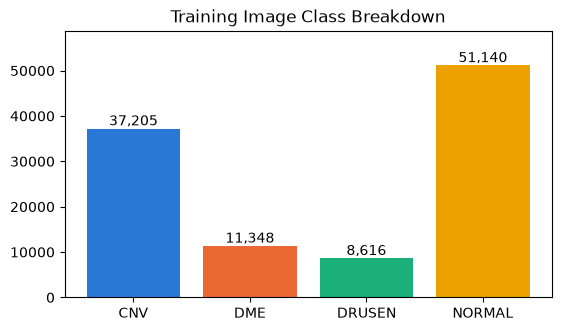

NORMAL has 5.9x as many observations as DRUSEN


In [12]:
train_counts = raw.loc[raw["split"] == "train", "class"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
class_bars(ax, train_counts, "Training Image Class Breakdown")
plt.show()
print(f"{train_counts.idxmax()} has {train_counts.max() / train_counts.min():.1f}x as many observations as {train_counts.idxmin()}")

### 1.2 patients by class

In [13]:
patients = raw.groupby(["split", "class"])["patient"].nunique().unstack()
patients.loc[SPLITS]

class,CNV,DME,DRUSEN,NORMAL
split,,,,
train,791,709,713,3434
test,178,167,169,171


### 1.3 patients found in more than one class

group images by patient ID to avoid leakage across splits

In [14]:
classes_per_patient = raw.groupby("patient")["class"].unique()
multi = classes_per_patient[classes_per_patient.apply(len) > 1]
print(f"{len(multi):,} of {len(classes_per_patient):,} patients span more than one class")
multi.apply(lambda c: " + ".join(sorted(c))).value_counts()

787 of 5,420 patients span more than one class


class
DME + NORMAL                   200
CNV + DRUSEN                   150
DRUSEN + NORMAL                136
CNV + NORMAL                   102
CNV + DME                       49
CNV + DRUSEN + NORMAL           39
DME + DRUSEN                    34
CNV + DME + NORMAL              25
CNV + DME + DRUSEN              24
DME + DRUSEN + NORMAL           19
CNV + DME + DRUSEN + NORMAL      9
Name: count, dtype: int64

### 1.4 resolutions

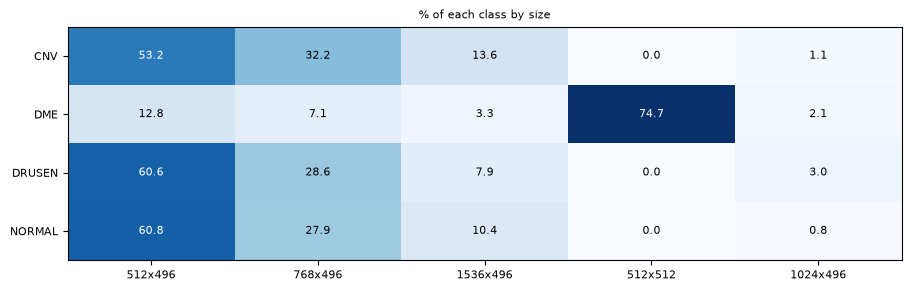

size,512x496,768x496,1536x496,512x512,1024x496,384x496,642x277,900x455
class,,,,,,,,
CNV,19912,12051,5076,0,401,15,0,0
DME,1485,818,388,8659,248,0,0,0
DRUSEN,5371,2532,699,0,262,0,1,1
NORMAL,31269,14348,5349,0,418,6,0,0


In [37]:
size_counts = pd.crosstab(raw["class"], raw["size"])
size_counts = size_counts[size_counts.sum().sort_values(ascending=False).index]  # most common size first
size_share = 100 * size_counts.div(size_counts.sum(axis=1), axis=0)
common = size_share.loc[:, size_counts.sum() >= 25]  # rare sizes are only in the table

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.imshow(common, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(common.columns)), common.columns)
ax.set_yticks(range(len(common.index)), common.index)
for i in range(len(common.index)):
    for j in range(len(common.columns)):
        value = common.iloc[i, j]
        color = "white" if value > 0.6 * common.values.max() else "black"
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", color=color)
ax.set_title("% of each class by size")
plt.show()
size_counts

### 1.5 pixel distribution by class

by percentile

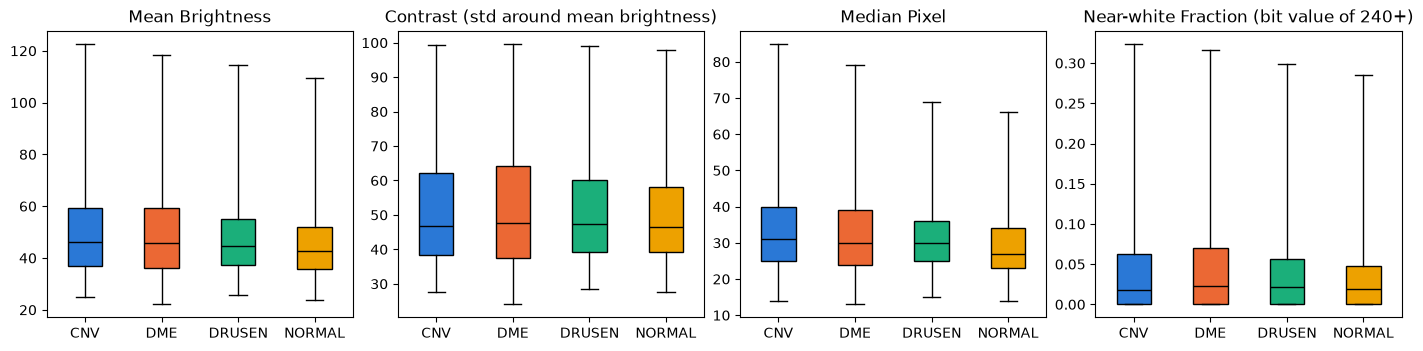

,mean,std,median,near_white
class,,,,
CNV,46.039,46.803,31.0,0.018
DME,45.799,47.781,30.0,0.022
DRUSEN,44.772,47.256,30.0,0.021
NORMAL,42.625,46.496,27.0,0.019


In [16]:
columns = ["mean", "std", "median", "near_white"]
titles = ["Mean Brightness", "Contrast (std around mean brightness)", "Median Pixel", "Near-white Fraction (bit value of 240+)"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, column, title in zip(axes, columns, titles):
    class_boxes(ax, raw, column, title)
plt.show()
raw.groupby("class")[columns].median().round(3)

### 1.6 wedge distribution by class

white wedges, detected by the presence of a white pixel with a value of 240 or higher in a corner of the image (same as we did in `standardize.py`)

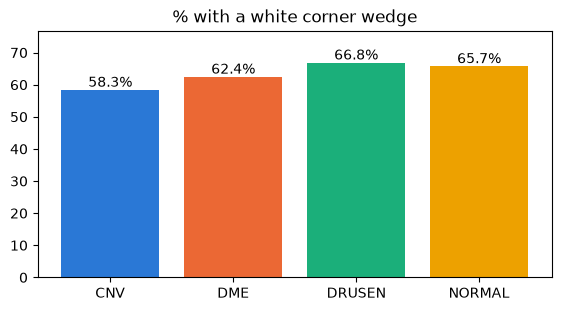

In [17]:
wedge_share = 100 * raw.groupby("class")["white_corner"].mean()
fig, ax = plt.subplots(figsize=(5.5, 3))
class_bars(ax, wedge_share, "% with a white corner wedge", fmt="{:.1f}%")
plt.show()

### 1.7 Example images per class

random sample of images, saved to to `raw_examples_by_class.png`

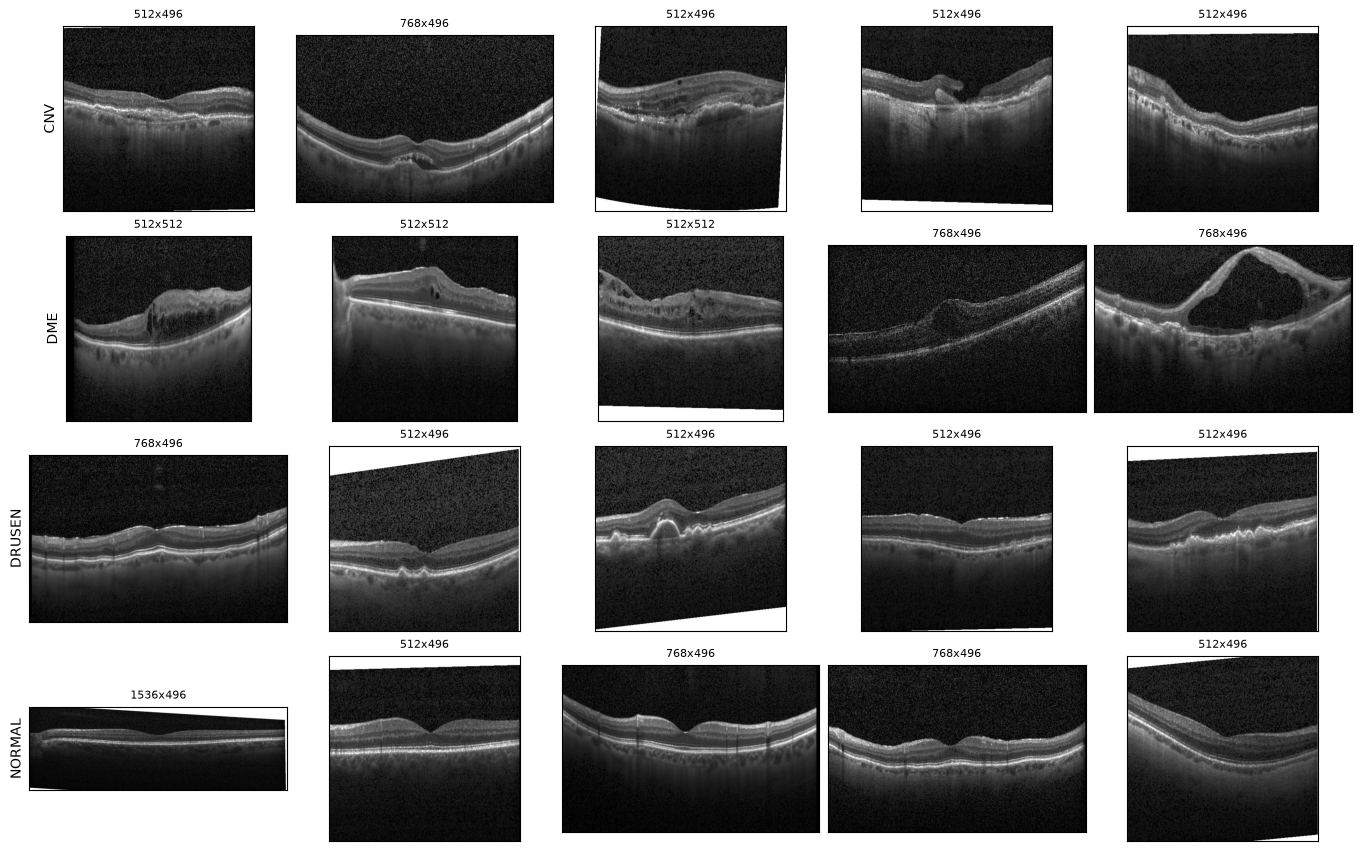

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(13.5, 8.4))
for i, class_name in enumerate(CLASSES):
    picks = raw[(raw["class"] == class_name) & (raw["split"] == "train")].sample(5, random_state=SEED)
    for j in range(5):
        row = picks.iloc[j]
        show_image(axes[i, j], DATA_FOLDER / row["file"], row["size"])
    axes[i, 0].set_ylabel(class_name)
fig.savefig("Figures/raw_examples_by_class.png", dpi=150)
plt.show()

## 2. leakage and duplicates

duplicates are identical or mirrored images per the same rules as used in `dupe.py`

In [19]:
readable = hashes[hashes["readable"] == "yes"].copy()
# an image and its mirror share the smaller of their two hashes, same as match_key in dupe.py
readable["key"] = readable.apply(lambda row: min(row["pixel_hash"], row["mirror_hash"]), axis=1)


def leakage(rows):
    """counts patients in both train and test, and groups of duplicate images"""
    train_patients = set(rows.loc[rows["split"] == "train", "patient"])
    test_patients = set(rows.loc[rows["split"] == "test", "patient"])
    group_sizes = rows["key"].value_counts()
    dupes = rows[rows["key"].isin(group_sizes[group_sizes > 1].index)]
    groups = dupes.groupby("key").agg(classes=("class", "nunique"), splits=("split", "nunique"),
                                      patients=("patient", "nunique"), versions=("pixel_hash", "nunique"))
    return pd.Series({
        "patients in train and test": len(train_patients & test_patients),
        "duplicate groups": len(groups),
        "duplicate images": len(dupes),
        "conflicting labels": (groups["classes"] > 1).sum(),
        "across train/test": (groups["splits"] > 1).sum(),
        "across patients": (groups["patients"] > 1).sum(),
        "with a mirror": (groups["versions"] > 1).sum(),
    })


cleaned_rows = readable[readable["file"].isin(log["file"])]
pd.DataFrame({"raw": leakage(readable), "cleaned": leakage(cleaned_rows)})

,raw,cleaned
patients in train and test,0,0
duplicate groups,7117,25
duplicate images,15008,50
conflicting labels,269,0
across train/test,0,0
across patients,44,25
with a mirror,0,0


### 2.1 files omitted per `dupe.py`

In [20]:
print(f"{len(omit):,} images omitted")
pd.crosstab(omit["reason"], omit["class"], margins=True, margins_name="total")

8,135 images omitted


class,CNV,DME,DRUSEN,NORMAL,total
reason,,,,,
conflicting labels,208,34,248,63,553
extra copy within training,5570,404,591,1017,7582
total,5778,438,839,1080,8135


## 3. cleaned data check

reads every cleaned PNG once

In [21]:
def read_clean(output):
    """opens one cleaned png and returns its size, pixel stats and retina height"""
    with Image.open(CLEAN_FOLDER / output) as image:
        size = f"{image.width}x{image.height}"
        mode = image.mode
        gray = image.convert("L")
    pixels = np.asarray(gray)
    hist = gray.histogram()
    # assume that the retinal height can be found by looking at
    # the row of the brightest horizontal band ineach row 
    # and smoothing over 9 rows to even out all the little dots
    row_means = pixels.mean(axis=1)
    smoothed = np.convolve(row_means, np.ones(9) / 9, mode="same")
    row = {"output": output, "size": size, "mode": mode,
           "near_black": sum(hist[:6]) / pixels.size, "band_row": smoothed.argmax()}
    row.update(histogram_stats(hist)) # uses our histogram_stats function to calculate mean, std, median, and p99 the cheap way
    return row


with ThreadPoolExecutor(THREADS) as pool:
    stats = pd.DataFrame(pool.map(read_clean, log["output"]))
clean = log.merge(stats, on="output")
print(f"{len(clean):,} cleaned images")

101,174 cleaned images


### 3.1 cleaning validation

In [22]:
raw_files = set(raw["file"]) | set(failed["file"])
omitted = set(omit["file"])
logged = set(log["file"])
should_be_cleaned = raw_files - omitted
pngs = {p.relative_to(CLEAN_FOLDER).as_posix() for p in CLEAN_FOLDER.rglob("*.png")}
outputs = set(log["output"])
expected_outputs = log["file"].apply(lambda f: Path(f).with_suffix(".png").as_posix())
omitted_pngs = {Path(f).with_suffix(".png").as_posix() for f in omitted}
size = f"{standardize.OUTPUT_WIDTH}x{standardize.OUTPUT_HEIGHT}"

counts = {
    "cleaned, should be omitted": len(logged - should_be_cleaned),
    "not cleaned": len(should_be_cleaned - logged),
    "logged, no png": len(outputs - pngs),
    "png, not logged": len(pngs - outputs),
    "png in wrong folder": (expected_outputs != log["output"]).sum(),
    "omitted, has png": len(omitted_pngs & pngs),
    f"not {size} grayscale": ((clean["size"] != size) | (clean["mode"] != "L")).sum(),
}

assert all(v == 0 for v in counts.values()), f"problems found: {counts}"
print("pass")

pass


### 3.2 pixel distribution and wedges by class

near-black pixels (5 or less) come from filled in wedges (pure black), padding under short scans (pure black), and dark backgrounds (probably not pure black)

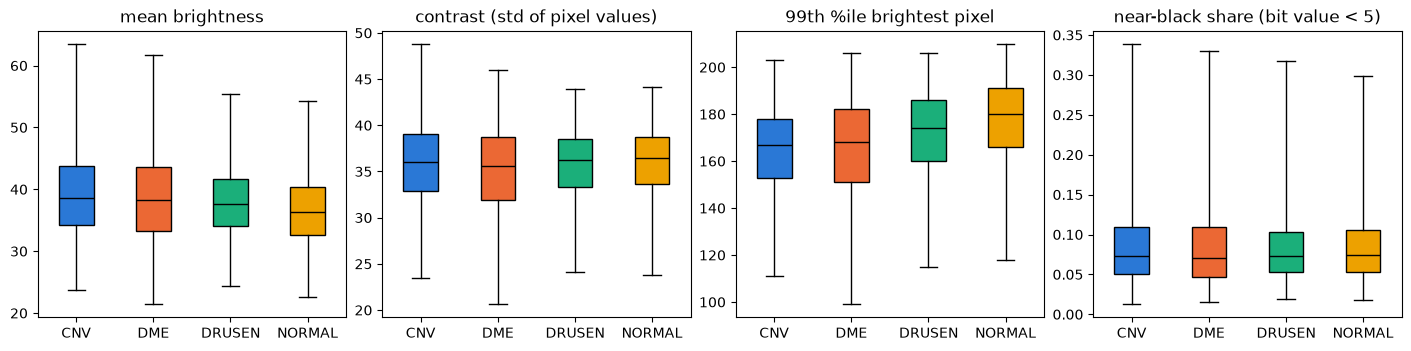

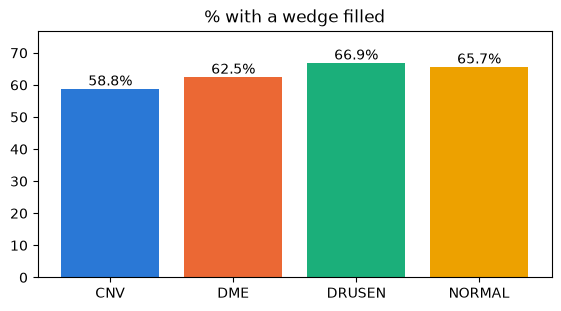

,mean,std,p99,near_black
class,,,,
CNV,38.673,36.065,167.0,0.073
DME,38.301,35.601,168.0,0.071
DRUSEN,37.622,36.252,174.0,0.073
NORMAL,36.393,36.420,180.0,0.074


In [23]:
columns = ["mean", "std", "p99", "near_black"]
titles = ["mean brightness", "contrast (std of pixel values)", "99th %ile brightest pixel", "near-black share (bit value < 5)"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, column, title in zip(axes, columns, titles):
    class_boxes(ax, clean, column, title)
plt.show()

clean["filled"] = clean["white_corners_removed"] == "yes" # whether the wedge was filled in by standardize.py
fig, ax = plt.subplots(figsize=(5.5, 3))
class_bars(ax, 100 * clean.groupby("class")["filled"].mean(), "% with a wedge filled", fmt="{:.1f}%")
plt.show()
clean.groupby("class")[columns].median().round(3)

### 3.3 retina height by class

assumes that the retinal height can be found by looking at the row of the brightest horizontal band in each row and smoothing over 9 rows to even out all the little dots in the background of each image
row 0 is the top row of the image

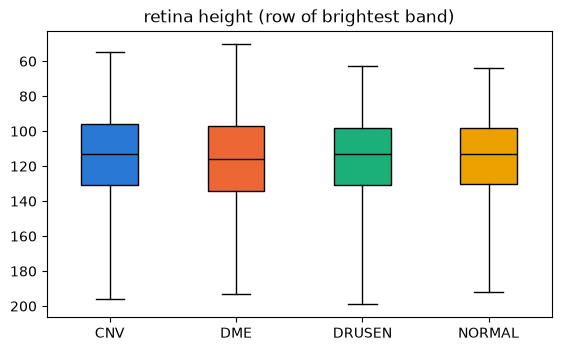

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
CNV,31677.0,115.3,28.8,4.0,96.0,113.0,131.0,243.0
DME,11160.0,116.8,29.8,4.0,97.0,116.0,134.0,235.0
DRUSEN,8027.0,116.1,27.1,4.0,98.0,113.0,131.0,233.0
NORMAL,50310.0,115.4,25.5,4.0,98.0,113.0,130.0,237.0


In [24]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
class_boxes(ax, clean, "band_row", "retina height (row of brightest band)")
ax.invert_yaxis()  # so the top of the chart is the top of the image
plt.show()
clean.groupby("class")["band_row"].describe().round(1)

### 3.4 cleaning comparison by width

compare before and after of images with different widths, saved to `cleaned_examples_by_width.png`

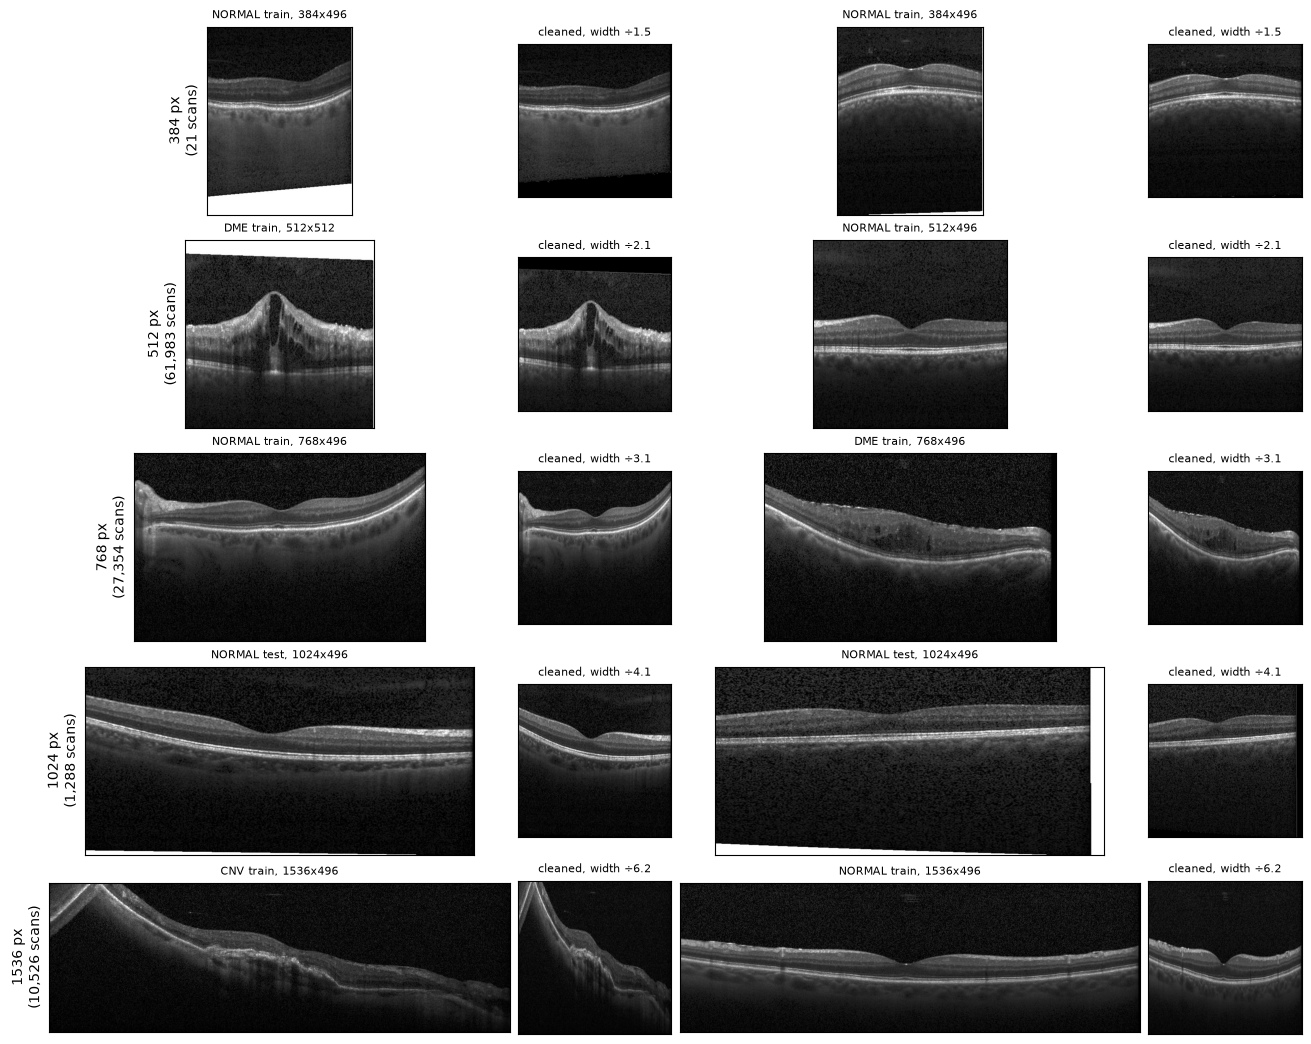

In [ ]:
scans_per_width = clean["width"].value_counts().sort_index()
widths = scans_per_width[scans_per_width >= 20].index  # widths that have at least 20 examples

fig, axes = plt.subplots(len(widths), 4, figsize=(13, 2.1 * len(widths)), width_ratios=[3, 1, 3, 1])
for i, width in enumerate(widths): # loop over the widths with at least 20 scans
    picks = clean[clean["width"] == width].sample(2, random_state=SEED) # pick two random images for this width
    for k in range(2):
        row = picks.iloc[k] # pick one of the two random images for this width
        show_image(axes[i, 2 * k], DATA_FOLDER / row["file"], f"{row['class']} {row['split']}, {width}x{row['height']}") # original
        show_image(axes[i, 2 * k + 1], CLEAN_FOLDER / row["output"], f"cleaned, width ÷{width / standardize.OUTPUT_WIDTH:.1f}") # cleaned
    axes[i, 0].set_ylabel(f"{width} px\n({scans_per_width[width]:,} scans)")
fig.savefig("Figures/cleaned_examples_by_width.png", dpi=150)
plt.show()

### 3.5 cleaning comparison by class

before and after of random images that had a wedge filled in, written to `cleaned_examples_by_class.png`

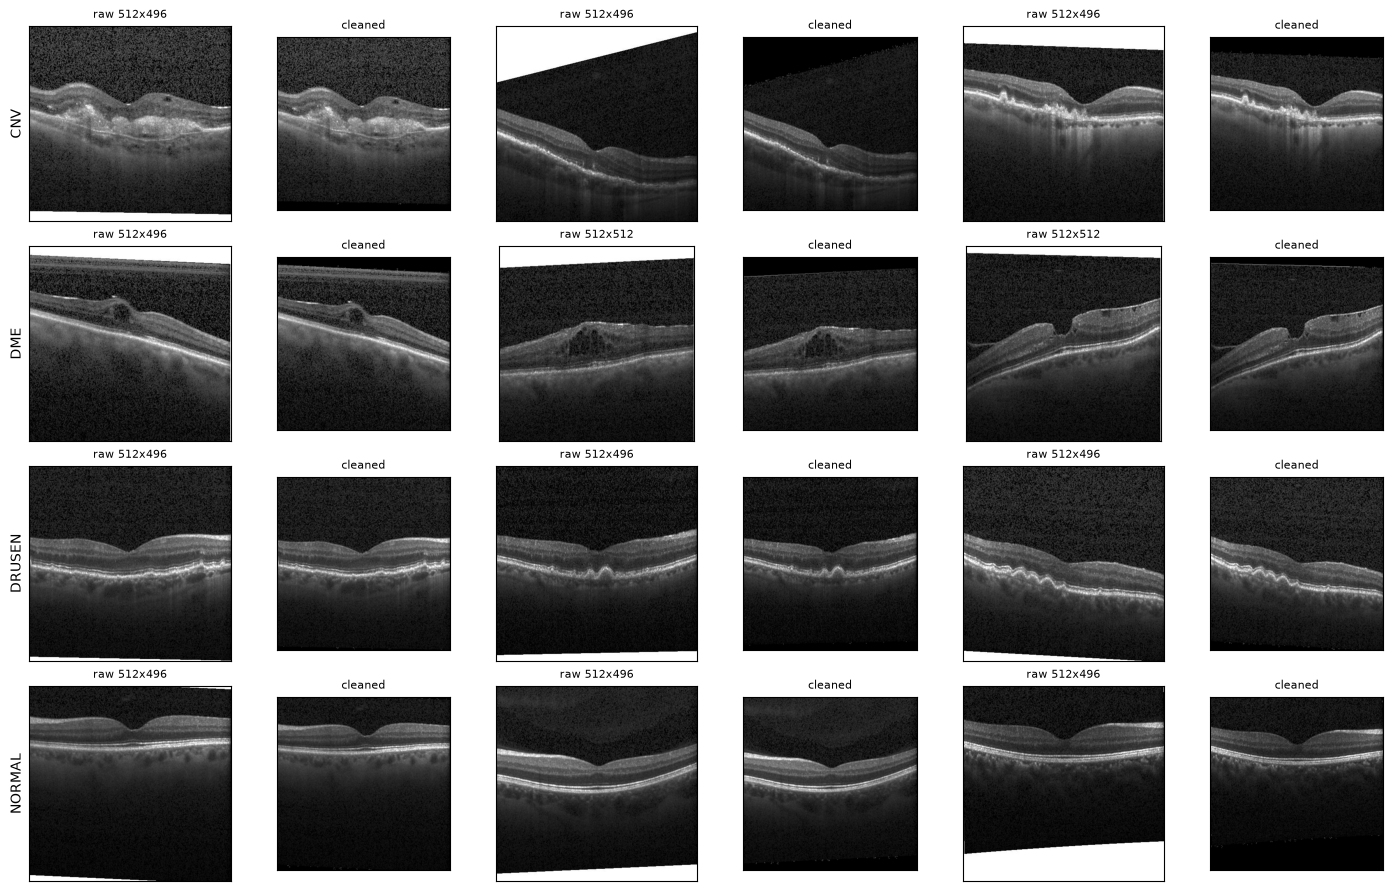

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(14, 8.8), width_ratios=[1.6, 1] * 3)
for i, class_name in enumerate(CLASSES): # one row per class
    candidates = clean[(clean["class"] == class_name) & (clean["white_corners_removed"] == "yes")] # images that had a wedge filled
    picks = candidates.sample(3, random_state=SEED) # pick three random images for this class
    for k in range(3):
        row = picks.iloc[k]
        show_image(axes[i, 2 * k], DATA_FOLDER / row["file"], f"raw {row['width']}x{row['height']}") # original
        show_image(axes[i, 2 * k + 1], CLEAN_FOLDER / row["output"], "cleaned") # cleaned
    axes[i, 0].set_ylabel(class_name)
fig.savefig("Figures/cleaned_examples_by_class.png", dpi=150)
plt.show()

## 4. training-split EDA and input pipeline

run `split.py` after `standardize.py` prior to executing these cells

In [27]:
import time

import keras
import tensorflow as tf

import pipeline
import split

REPORT_FIGURES = DATA_FOLDER / "figures"
REPORT_FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "savefig.dpi": 300})
# the amber NORMAL used above is too close to the orange DME (a palette validator puts the pair
# below the minimum colour difference), so the report figures use magenta for NORMAL
CLASS_COLORS["NORMAL"] = "#c2489a"
COLORS = [CLASS_COLORS[c] for c in CLASSES]
PARTS = ["train", "val", "test"]

splits = pd.read_csv(split.SPLITS_CSV, dtype=str)
parts = clean.merge(splits[["file", "split", "patient", "group"]].rename(columns={"split": "part"}), on="file")
parts["size"] = parts["width"].astype(str) + "x" + parts["height"].astype(str)
train = parts[parts["part"] == "train"]
print({part: f"{(parts['part'] == part).sum():,}" for part in PARTS})

{'train': '80,136', 'val': '20,038', 'test': '1,000'}


### 4.1 summary: class balance, patients, scan size + brightness

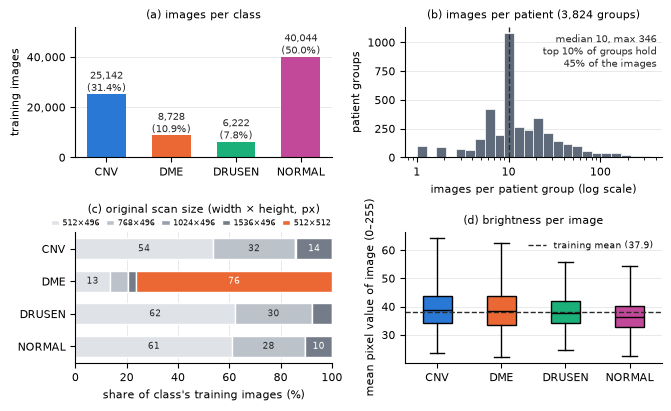

In [34]:
from matplotlib.ticker import FuncFormatter

INK = "#2b2b2b" # darker color for visibility on lighter backgrounds
THOUSANDS = FuncFormatter(lambda x, _: f"{x:,.0f}")


def tidy(ax, grid_axis="y"):
    """remove top and right spines, add a light grid, put the grid behind the data"""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grid_axis, color="#e3e5e8", linewidth=0.6)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(2, 2, figsize=(6.6, 4.0))
(ax_a, ax_b), (ax_c, ax_d) = axes

# a. class balance
counts = train["class"].value_counts()[CLASSES]
bars = ax_a.bar(CLASSES, counts, color=COLORS, width=0.6)
ax_a.bar_label(bars, labels=[f"{n:,}\n({100 * n / counts.sum():.1f}%)" for n in counts], fontsize=7, color=INK) # label each bar with the number of images and the percentage of the total
ax_a.set_ylabel("training images")
ax_a.set_ylim(0, counts.max() * 1.3)
ax_a.yaxis.set_major_formatter(THOUSANDS)
ax_a.set_title("(a) images per class")
tidy(ax_a)

# b. images per patient group
per_group = train.groupby("group").size()
top_share = per_group.sort_values(ascending=False).head(len(per_group) // 10).sum() / per_group.sum()
ax_b.hist(per_group, bins=np.logspace(0, np.log10(per_group.max() + 1), 25),
          color="#5f6b7a", edgecolor="white", linewidth=0.5)
ax_b.set_xscale("log")
ax_b.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax_b.axvline(per_group.median(), color=INK, linestyle="--", linewidth=1)
ax_b.text(0.98, 0.95, f"median {per_group.median():.0f}, max {per_group.max()}\n" # median and max number of images per patient group
          f"top 10% of groups hold\n{100 * top_share:.0f}% of the images",
          transform=ax_b.transAxes, fontsize=7, ha="right", va="top", color=INK)
ax_b.set_xlabel("images per patient group (log scale)")
ax_b.set_ylabel("patient groups")
ax_b.set_title(f"(b) images per patient ({len(per_group):,} groups)")
tidy(ax_b)

# c. original scan size, 512x512 highlighted since only DME has it
SIZES = ["512x496", "768x496", "1024x496", "1536x496", "512x512"]
SIZE_COLORS = ["#dfe2e6", "#bcc2ca", "#98a0ab", "#737c88", CLASS_COLORS["DME"]] # darkening shades of grey with exception for DME
share = 100 * pd.crosstab(train["class"], train["size"], normalize="index").reindex(columns=SIZES, fill_value=0)
share = share.loc[CLASSES[::-1]]  # CNV on top
left = np.zeros(len(share)) # the left edge of the next bar segment
for size, color in zip(SIZES, SIZE_COLORS):
    ax_c.barh(share.index, share[size], left=left, color=color, edgecolor="white", linewidth=1, height=0.65, label=size.replace("x", "×"))
    for y, (x0, width) in enumerate(zip(left, share[size])): # loop over the bars for this size
        if width >= 9:  # only label segments wide enough to hold the number
            ax_c.text(x0 + width / 2, y, f"{width:.0f}", ha="center", va="center", fontsize=6.5,
                      color="white" if size in ("1536x496", "512x512") else INK) # bars in white text for the two darkest colors, dark text for the rest
    left += share[size].to_numpy()
ax_c.set_xlim(0, 100)
ax_c.set_xlabel("share of class's training images (%)")
ax_c.legend(ncols=5, fontsize=6, frameon=False, loc="lower center", bbox_to_anchor=(0.45, 0.98), handlelength=1, handletextpad=0.4, columnspacing=0.8)
ax_c.set_title("(c) original scan size (width × height, px)", pad=14)
tidy(ax_c, "x")

# d. brightness of each cleaned image. every image has the same number of pixels, so the mean of the
# image means is the training pixel mean that the pipeline normalizes with
class_boxes(ax_d, train, "mean", "(d) brightness per image")
train_mean = train["mean"].mean() # this is obtained from our histogram cheat that we called in read_clean() in sec 3 above, to save time and resources
ax_d.axhline(train_mean, color=INK, linestyle="--", linewidth=1, label=f"training mean ({train_mean:.1f})")
ax_d.set_ylabel("mean pixel value of image (0–255)")
ax_d.legend(fontsize=6.5, frameon=False, loc="upper right")
tidy(ax_d)

fig.savefig("Figures/eda_train.png", dpi=400)
plt.show()

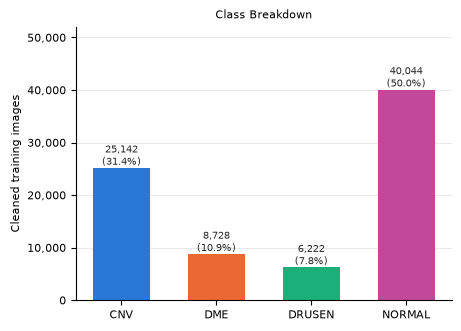

In [33]:
# (a) class balance, on its own
counts = train["class"].value_counts()[CLASSES]
fig, ax = plt.subplots(figsize=(4.5, 3.2))
bars = ax.bar(CLASSES, counts, color=COLORS, width=0.6)
ax.bar_label(bars, labels=[f"{n:,}\n({100 * n / counts.sum():.1f}%)" for n in counts], fontsize=7, color=INK) # number of images and share of the total
ax.set_ylabel("Cleaned training images")
ax.set_ylim(0, counts.max() * 1.3)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_title("Class Breakdown")
tidy(ax)
plt.show()

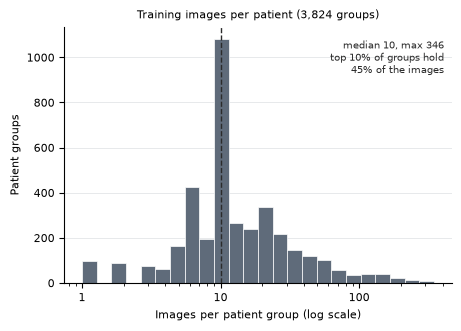

In [36]:
# (b) images per patient group, on its own
per_group = train.groupby("group").size()
top_share = per_group.sort_values(ascending=False).head(len(per_group) // 10).sum() / per_group.sum()
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.hist(per_group, bins=np.logspace(0, np.log10(per_group.max() + 1), 25),
        color="#5f6b7a", edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax.axvline(per_group.median(), color=INK, linestyle="--", linewidth=1)
ax.text(0.98, 0.95, f"median {per_group.median():.0f}, max {per_group.max()}\n"
        f"top 10% of groups hold\n{100 * top_share:.0f}% of the images",
        transform=ax.transAxes, fontsize=7, ha="right", va="top", color=INK)
ax.set_xlabel("Images per patient group (log scale)")
ax.set_ylabel("Patient groups")
ax.set_title(f"Training images per patient ({len(per_group):,} groups)")
tidy(ax)
plt.show()

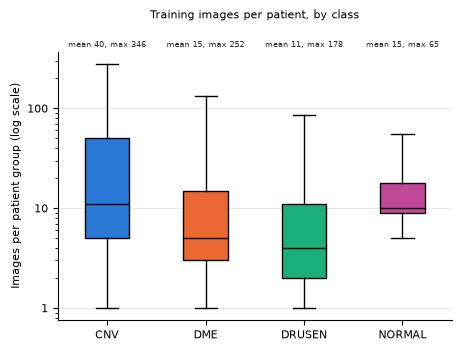

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
CNV,626.0,40.2,60.4,1.0,5.0,11.0,51.0,346.0
DME,565.0,15.4,26.6,1.0,3.0,5.0,15.0,252.0
DRUSEN,574.0,10.8,17.6,1.0,2.0,4.0,11.0,178.0
NORMAL,2745.0,14.6,10.2,1.0,9.0,10.0,18.0,65.0


In [38]:
# images per patient group, split by class. a group with images in more than one class counts once in each
per_group_class = train.groupby(["class", "group"]).size().rename("images").reset_index()
fig, ax = plt.subplots(figsize=(4.5, 3.4))
class_boxes(ax, per_group_class, "images", "Training images per patient, by class")
ax.set_title(ax.get_title(), pad=24)  # room for the mean/max labels above the boxes
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
ax.set_ylabel("Images per patient group (log scale)")
for x, class_name in enumerate(CLASSES, start=1): # mean and max sit above each box, since the whiskers stop at the 99th percentile
    images = per_group_class.loc[per_group_class["class"] == class_name, "images"]
    ax.text(x, 1.01, f"mean {images.mean():.0f}, max {images.max()}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=6, color=INK)
tidy(ax)
fig.savefig("Figures/eda_images_per_patient_by_class.png", dpi=400)
plt.show()
per_group_class.groupby("class")["images"].describe().round(1)

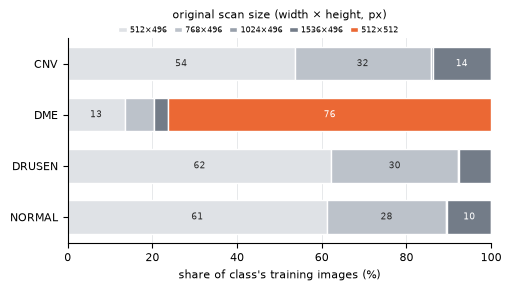

In [41]:
# (c) original scan size by class, on its own. uses SIZES and SIZE_COLORS from the summary cell
share = 100 * pd.crosstab(train["class"], train["size"], normalize="index").reindex(columns=SIZES, fill_value=0)
share = share.loc[CLASSES[::-1]]  # CNV on top
fig, ax = plt.subplots(figsize=(5, 2.8))
left = np.zeros(len(share)) # the left edge of the next bar segment
for size, color in zip(SIZES, SIZE_COLORS):
    ax.barh(share.index, share[size], left=left, color=color, edgecolor="white", linewidth=1, height=0.65, label=size.replace("x", "×"))
    for y, (x0, width) in enumerate(zip(left, share[size])):
        if width >= 9:  # only label segments wide enough to hold the number
            ax.text(x0 + width / 2, y, f"{width:.0f}", ha="center", va="center", fontsize=6.5,
                    color="white" if size in ("1536x496", "512x512") else INK)
    left += share[size].to_numpy()
ax.set_xlim(0, 100)
ax.set_xlabel("share of class's training images (%)")
ax.legend(ncols=5, fontsize=6, frameon=False, loc="lower center", bbox_to_anchor=(0.45, 0.98), handlelength=1, handletextpad=0.4, columnspacing=0.8)
ax.set_title("original scan size (width × height, px)", pad=14)
tidy(ax, "x")
fig.savefig("Figures/eda_scan_size.png", dpi=400)
plt.show()

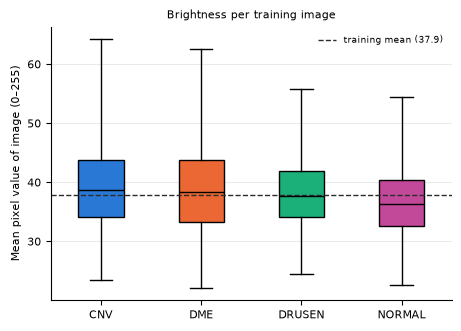

In [40]:
# (d) brightness per cleaned image, on its own
fig, ax = plt.subplots(figsize=(4.5, 3.2))
class_boxes(ax, train, "mean", "Brightness per training image")
train_mean = train["mean"].mean() # same as the pipeline's training pixel mean, since every image has the same number of pixels
ax.axhline(train_mean, color=INK, linestyle="--", linewidth=1, label=f"training mean ({train_mean:.1f})")
ax.set_ylabel("Mean pixel value of image (0–255)")
ax.legend(fontsize=6.5, frameon=False, loc="upper right")
tidy(ax)
fig.savefig("Figures/eda_brightness.png", dpi=400)
plt.show()

### 4.2 normalization stats

computed by `pipeline.py` from train split only, saved to `norm_stats.csv`

In [ ]:
# every split is scaled by these same two numbers as determined by the training set
stats = pipeline.train_stats()
print(f"training pixel mean {stats['mean']:.2f}, std {stats['std']:.2f}, from {stats['train_images']:,} images")

training pixel mean 38.88, std 36.24, from 80,136 images


### 4.3 pipeline check

In [ ]:
def full_pass(ds):
    """time one pass over a dataset, counting the labels as they come out of the pipeline"""
    started = time.perf_counter()
    counts = np.zeros(len(CLASSES), dtype=int)
    for _, labels in ds:
        counts += np.bincount(labels.numpy(), minlength=len(CLASSES))
    return time.perf_counter() - started, counts


# the first pass reads and decodes every PNG from disk and fills the in-memory cache, later passes read the cache
datasets = {part: pipeline.make_dataset(part) for part in PARTS}
first_pass = {}
for part in PARTS:
    first_pass[part], counts = full_pass(datasets[part])
    expected = parts.loc[parts["part"] == part, "class"].value_counts()[CLASSES].to_numpy()
    assert (counts == expected).all(), f"{part}: pipeline labels {counts} != splits.csv {expected}"
    print(f"{part:<5} first pass {first_pass[part]:5.1f} s, labels per class {counts.tolist()} match splits.csv")
cached_pass, _ = full_pass(datasets["train"])
batches = int(np.ceil((parts["part"] == "train").sum() / pipeline.BATCH_SIZE))
print(f"train cached pass {cached_pass:.1f} s ({batches:,} batches of {pipeline.BATCH_SIZE}, "
      f"{(parts['part'] == 'train').sum() / cached_pass:,.0f} images/s)")

train first pass  16.3 s, labels per class [25142, 8728, 6222, 40044] match splits.csv
val   first pass   3.7 s, labels per class [6285, 2182, 1555, 10016] match splits.csv
test  first pass   0.2 s, labels per class [250, 250, 250, 250] match splits.csv
train cached pass 3.4 s (1,253 batches of 64, 23,373 images/s)


### 4.4 one batch from each pipeline

In [ ]:
# one batch from the end of each pipeline. val and test are not shuffled, so their first batch is all CNV
for part in PARTS:
    images, labels = next(iter(datasets[part]))
    print(f"{part:<5} images {tuple(images.shape)} {images.dtype.name}, labels {tuple(labels.shape)} {labels.dtype.name}, "
          f"label values {sorted(set(labels.numpy().tolist()))}, "
          f"pixels mean {float(tf.reduce_mean(images)):+.2f} std {float(tf.math.reduce_std(images)):.2f}")

train images (64, 248, 248, 1) float32, labels (64,) int32, label values [0, 1, 2, 3], pixels mean +0.05 std 1.02
val   images (64, 248, 248, 1) float32, labels (64,) int32, label values [0], pixels mean +0.05 std 1.01
test  images (64, 248, 248, 1) float32, labels (64,) int32, label values [0], pixels mean +0.08 std 1.03


### 4.5 smoke test

In [ ]:
# smoke test: the smallest possible model, flatten + one dense layer, trained for 300 steps on the training pipeline
# params are pretty arbitrary here, we just wanna make sure everything works, no need to actually optimize stuff yet

keras.utils.set_random_seed(SEED)
smoke = keras.Sequential([keras.Input(pipeline.INPUT_SHAPE), keras.layers.Flatten(), keras.layers.Dense(len(CLASSES))])
smoke.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
SMOKE_BLOCKS, BLOCK_STEPS = 30, 10  # keras reports the mean loss of each block of 10 steps
started = time.perf_counter() # time the training so we can report how long it took
history = smoke.fit(datasets["train"], epochs=SMOKE_BLOCKS, steps_per_epoch=BLOCK_STEPS, shuffle=False, verbose=0)
smoke_loss = np.array(history.history["loss"])
prior = train["class"].value_counts(normalize=True)
prior_loss = -(prior * np.log(prior)).sum()  # the loss of a model that only knows the class shares
print(f"{SMOKE_BLOCKS * BLOCK_STEPS} steps in {time.perf_counter() - started:.1f} s, {smoke.count_params():,} parameters")
print(f"loss {smoke_loss[0]:.3f} over the first 10 steps -> {smoke_loss[-1]:.3f} over the last 10 "
      f"(uniform guess {np.log(len(CLASSES)):.3f}, class shares only {prior_loss:.3f})")
val_loss, val_accuracy = smoke.evaluate(datasets["val"], verbose=0)
print(f"accuracy over the last 10 steps {history.history['accuracy'][-1]:.3f}, val loss {val_loss:.3f}, val accuracy {val_accuracy:.3f}")

300 steps in 1.9 s, 246,020 parameters
loss 1.604 over the first 10 steps -> 1.118 over the last 10 (uniform guess 1.386, class shares only 1.150)
accuracy over the last 10 steps 0.558, val loss 1.099, val accuracy 0.582


### 4.6 report figure: denormalized view of image input + smoke test visualization

titles are the true labels read from the batch. our smoke model makes NO predictions here.

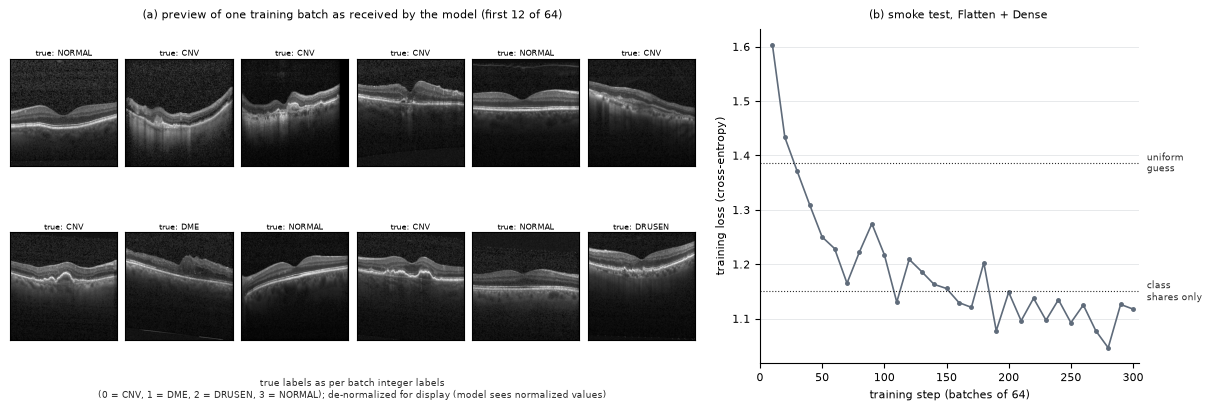

In [ ]:
# preview of one training batch from the end of the pipeline with the normalization undone so that it looks better to us
# (it looks different to the machine as it uses normalized pixel values instead of 0-255)
# each title is the true label, decoded from the batch's own label tensor rather than looked up from the file
# labels that mismatch their corresponding image would show up here. the smoke model doesn't make any predictions here
images, labels = next(iter(datasets["train"]))
shown = pipeline.denormalize(images[:12])
fig = plt.figure(figsize=(12, 4))
left, right = fig.subfigures(1, 2, width_ratios=[7, 5])
for k, ax in enumerate(left.subplots(2, 6).flat):
    ax.imshow(shown[k, :, :, 0], cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"true: {CLASSES[int(labels[k])]}", fontsize=6, pad=2)
left.suptitle(f"(a) preview of one training batch as received by the model (first 12 of {pipeline.BATCH_SIZE})", fontsize=8)
left.supxlabel("true labels as per batch integer labels\n"
               f"({', '.join(f'{i} = {c}' for i, c in enumerate(CLASSES))}); de-normalized for display (model sees normalized values)",
               fontsize=6.5, color=INK)

ax = right.subplots()
steps = BLOCK_STEPS * np.arange(1, SMOKE_BLOCKS + 1)
ax.plot(steps, smoke_loss, color="#5f6b7a", marker="o", markersize=2.5, linewidth=1.2)
# reference lines are labelled just outside the right edge, where the loss curve can't run over the text
for level, text in [(np.log(len(CLASSES)), "uniform\nguess"), (prior_loss, "class\nshares only")]:
    ax.axhline(level, color=INK, linestyle=":", linewidth=0.8)
    ax.text(1.02, level, text, transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=6.5, color=INK)
ax.set_xlim(0, steps[-1] + 5)
ax.set_xlabel("training step (batches of 64)")
ax.set_ylabel("training loss (cross-entropy)")
right.suptitle("(b) smoke test, Flatten + Dense", fontsize=8)
tidy(ax)
fig.savefig("Figures/pipeline_batch_smoke.png")
plt.show()

### 4.7 sample of normalized image inputs

just in case

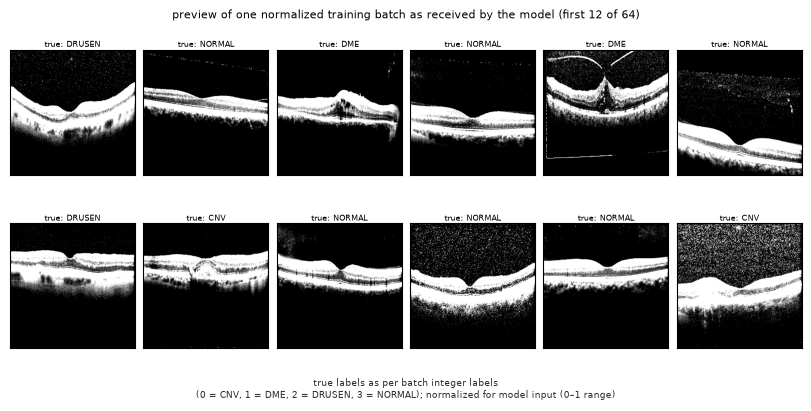

In [ ]:
images, labels = next(iter(datasets["train"]))
# show the normalized pixel values that the model actually sees, rather than the de-normalized values above
shown = images[:12]
fig = plt.figure(figsize=(8, 4))
for k, ax in enumerate(fig.subplots(2, 6).flat):
    ax.imshow(shown[k, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"true: {CLASSES[int(labels[k])]}", fontsize=6, pad=2)
suptitle = fig.suptitle(f"preview of one normalized training batch as received by the model (first 12 of {pipeline.BATCH_SIZE})", fontsize=8)
suptitle.set_y(0.95)
supxlabel = fig.supxlabel("true labels as per batch integer labels\n"
                          f"({', '.join(f'{i} = {c}' for i, c in enumerate(CLASSES))}); normalized for model input (0–1 range)",
                          fontsize=6.5, color=INK)
fig.savefig("Figures/normalized previews.png")
plt.show()